--- Q1: Generate Data ---
Total observations: 300


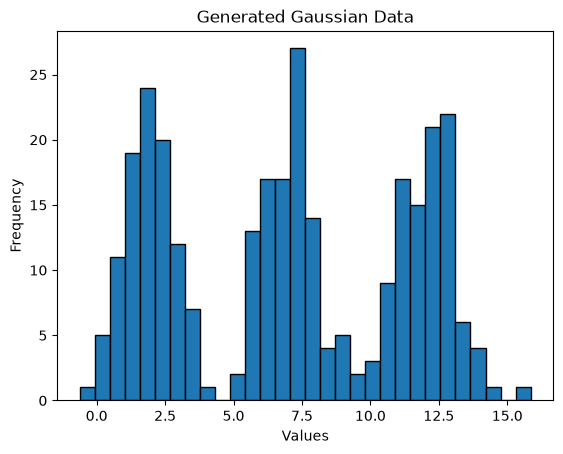

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

print("--- Q1: Generate Data ---")
np.random.seed(42)
group1 = np.random.normal(2, 1, 100)
group2 = np.random.normal(7, 1, 100)
group3 = np.random.normal(12, 1, 100)

data = np.concatenate([group1, group2, group3])
X = data.reshape(-1, 1)
print("Total observations:", len(X))

# Plot histogram
plt.hist(X, bins=30, edgecolor="black")
plt.title("Generated Gaussian Data")
plt.xlabel("Values")
plt.ylabel("Frequency")
plt.show()

In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


--- Q2: Apply GMM ---
First 20 labels: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


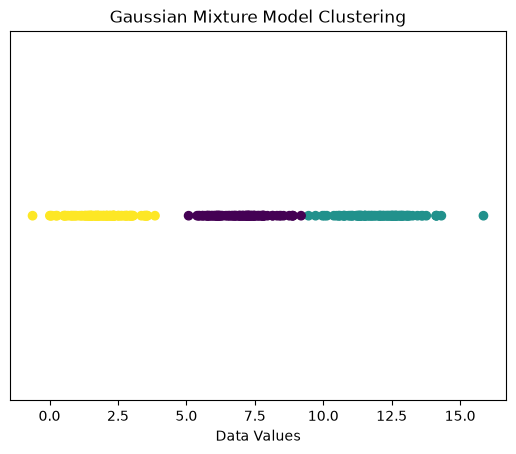

In [2]:
print("--- Q2: Apply GMM ---")
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(X)

labels = gmm.predict(X)
print("First 20 labels:", labels[:20])

# Plot clustering results
plt.scatter(X[:, 0], np.zeros(len(X)), c=labels, cmap="viridis")
plt.title("Gaussian Mixture Model Clustering")
plt.xlabel("Data Values")
plt.yticks([])
plt.show()

In [3]:
print("--- Q3: Estimated Model Parameters ---")
print("Estimated Means:\n", gmm.means_)
print("\nEstimated Variances:\n", gmm.covariances_)
print("\nMixing Proportions:\n", gmm.weights_)

--- Q3: Estimated Model Parameters ---
Estimated Means:
 [[ 6.98734645]
 [12.04041718]
 [ 1.89614955]]

Estimated Variances:
 [[[0.8221013 ]]

 [[1.19793122]]

 [[0.81819915]]]

Mixing Proportions:
 [0.32957963 0.33717043 0.33324994]


--- Q4: BIC for Model Selection ---
Components: 1 | BIC: 1733.11
Components: 2 | BIC: 1655.28
Components: 3 | BIC: 1526.83
Components: 4 | BIC: 1545.74


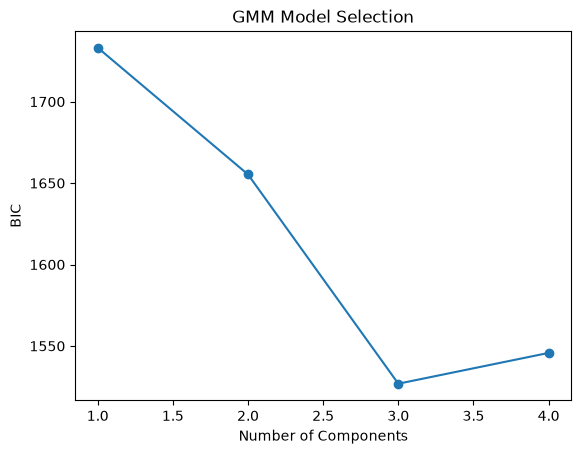

In [4]:
print("--- Q4: BIC for Model Selection ---")
components = [1, 2, 3, 4]
bic_values = []

for k in components:
    model = GaussianMixture(n_components=k, random_state=42)
    model.fit(X)
    bic = model.bic(X)
    bic_values.append(bic)
    print(f"Components: {k} | BIC: {bic:.2f}")

# Plot BIC values
plt.plot(components, bic_values, marker="o")
plt.xlabel("Number of Components")
plt.ylabel("BIC")
plt.title("GMM Model Selection")
plt.show()

## LAB 14: Questions & Answers





**1. Define the EM algorithm.**
*Answer:* The Expectation-Maximization (EM) algorithm is an iterative method used to find maximum likelihood estimates of parameters in statistical models, where the model depends on unobserved latent variables (hidden groups).

**2. What is a Gaussian Mixture Model?**
*Answer:* A Gaussian Mixture Model (GMM) is a probabilistic model that assumes all the data points are generated from a mixture of a finite number of Gaussian distributions with unknown parameters.

**3. Explain the difference between the E-step and M-step.**
*Answer:* The **E-step (Expectation)** calculates the probability that each data point belongs to each cluster based on current parameters. The **M-step (Maximization)** updates the parameters (mean, variance, and weight) of each cluster using the probabilities calculated in the E-step to maximize the likelihood of the data.

**4. Why is clustering important in statistical computing?**
*Answer:* Clustering is important because it helps discover natural groupings or patterns in unlabeled data. It is widely used in market segmentation, image processing, and anomaly detection to make sense of large datasets.

**5. What is the purpose of n_components?**
*Answer:* In scikit-learn's `GaussianMixture`, `n_components` defines the number of underlying Gaussian distributions (clusters) we expect the algorithm to find in the data.

**6. Explain the importance of BIC.**
*Answer:* The Bayesian Information Criterion (BIC) is used for model selection. It penalizes models for having too many parameters, helping to prevent overfitting. A lower BIC indicates a better balance between model fit and complexity.

**7. What does the fit() function do?**
*Answer:* The `fit()` function trains the model on the provided data. In the context of GMM, it runs the EM algorithm iteratively to find the optimal parameters (means, covariances, and weights) for the distributions.

**8. Mention two practical applications of GMM.**
*Answer:* 
1. **Image Segmentation:** Grouping pixels into different regions based on color or texture.
2. **Speaker Recognition:** Modeling the voice characteristics of different speakers to identify who is talking.